# **POLAR Task 3: Manifestion Identification**

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)


In [2]:
%pwd

'/home/thant_syn/exp/polar'

In [3]:
%cd processed/

/home/thant_syn/exp/polar/processed


In [4]:
!head -n 10 task3_polarization_manifestation_no_id.txt

text|stereotype|vilification|dehumanization|extreme_language|lack_of_empathy|invalidation
ကိုယ့်နိုင်ငံကြီး အေးချမ်းသွားရင် ကိုယ့်နိုင်ငံ ပြန်တာပေါ့ သူတို့နိုင်ငံမှာ အရမ်း အနှိမ်ခံ ရတယ်ဗျာ|1|0|0|0|1|0
တကယ် လေ နိုင်ငံခြား သား တွေ အကုန် လုံး ကို တစ် ယောက် မ ကျန် အကုန် ပြန်လွှတ် စေ ချင် တာ ဂျပန် မှ လွဲ အကုန်လုံး ကို အဲ့လို သာ လုပ် လိုက် သူတို့ နိုင်ငံ သေချာပေါက် စီးပွားရေး ကျ ဆင်း ကုန်မှာ အေးရော။|1|0|0|0|1|0
ဂျပန် ထဲ မြန်မာ တွေ ဝင် လာ ပြီ ဆိုတော့ သူတို့ လန့် သွား တယ် ထင်တယ်|1|0|0|0|0|0
ဒီ အကြောင်း တွေ ကို  ဂျပန် လို ပြော ပြီး  တင် သင့် တယ် အခု လည်း ခွဲခြား ခြင်း ခံ ရ ပါတယ် သူတို့ က နေရာ က လိုချင် အပါး က ခို|1|0|0|0|0|0
တရုတ် တွေ က ဂျပန် ကို မုန်း တယ် ပြော ပြီး ဘာလို့ အများ ကြီး ဂျပန် ကို ဝင်လာ ကြ တာ လဲ|1|0|0|0|0|0
တူတူ ပဲ မ ရေ အလုပ် ထဲ က သူနာပြု မ လူ ကို မ တူ သ လို မ တန် သ လို အချိုး အမျိုးမျိုး နဲ့ စကား ပြောတယ် ညီမ ဆေး တိုက် ချိန် သူ့ ကို ပြ ရင် လုံးဝ မ ကြည့် ဘူး ဘာမှ လည်း ပြန် မ ပြော ဘူး|0|0|0|0|1|0
ထိုင်း မှာ နေ ရ တာ အရမ်း ပင်ပန်း လာ ပြီ ဗျာ|0|0|0|0|0|1
ဘယ် ဥ က ပေါက် တဲ့ ကောင် လဲ မ သိ 

In [5]:
file_path = "task3_polarization_manifestation_no_id.txt"

with open(file_path, "r", encoding="utf-8") as f:
    for line_no, line in enumerate(f, start=1):
        if line.count("|") != 6:
            print(
                f"Line {line_no}: "
                f"{line.count('|')} separators"
            )
            print(repr(line[:250]))

Line 134: 0 separators
'"တော် ကြ ပါ တော့ နိုင်ငံရေး တွေ မ လုပ် ကြ ပါ နဲ့ တော့ ဘာမှ လဲ ဖြစ် မ လာ ဘူး\n'
Line 135: 5 separators
'1|1|0|0|0|0\n'
Line 174: 0 separators
'"မြန်မာ ပြည် က အခြေခံ လူတန်းစား တွေ ကို\n'
Line 175: 5 separators
'0|0|0|0|1|0\n'
Line 176: 0 separators
'"သိပ် ဝမ်းနည်း ဖို ကောင်း တယ် သူ များ နိုင်ငံ မှာ အနှိမ် ခံ ရ တာ ကို မ ပြော လို ဘူး\n'
Line 177: 5 separators
'0|0|0|0|1|1\n'
Line 451: 9 separators
'"ဟာရီစပါး သည် သူ့ မယား စိတ်ဆိုး နေ သည် ကို ရိပ် မိ သွား ဟန် ဖြင့် ခပ်စောစော က ||| အိပ် ပျော် နေ ရာ ပလက်ဖောင်း ပေါ် သို့ ပြန် ခွေ နေ လိုက်  သည်"|0|0|1|0|0|0\n'
Line 474: 0 separators
'"ညစ်ပတ် နောက် ကျိ\u200c နေ သော ရေ သည် မီးသတ်ပိုက် ခေါင်းမှ ဒလဟော ထွက်နေ ၏\n'
Line 475: 5 separators
'0|1|0|0|0|0\n'
Line 486: 0 separators
'"ဆင်းရဲသား ရပ်ကွက် တွေ မှာ ခင်ဗျား တကယ် သွား နေ မှာ လား နေ ကော နေ နိုင် ပါ့ မ လား \n'
Line 487: 5 separators
'1|1|0|0|0|0\n'
Line 1942: 7 separators
'"စစ်တပ်ကပြန်ပြီးreformလုပ်မှရမယ်ပြီးတော့အဲ့ဒီစစ်တပ်ထဲးမှာတိုင်းရင်းသားအများစုကိုထည့်သွင်းဖွဲ့စည်းမှရမယ်အခ

In [6]:
import re
import csv
import pandas as pd
from pathlib import Path

input_file = Path("task3_polarization_manifestation_no_id.txt")
output_file = Path("task3_repaired.csv")

label_cols = [
    "stereotype",
    "vilification",
    "dehumanization",
    "extreme_language",
    "lack_of_empathy",
    "invalidation",
]

label_pattern = re.compile(r"^[01](?:\|[01]){5}$")

records = []
pending_text = []

with input_file.open("r", encoding="utf-8-sig") as f:
    lines = f.readlines()

# Skip the header
for line in lines[1:]:
    line = line.rstrip("\r\n")

    # Case 1: labels appear alone on a separate line
    if label_pattern.fullmatch(line.strip()):
        if not pending_text:
            print("Warning: labels without preceding text:", line)
            continue

        text = "\n".join(pending_text).strip()
        pending_text = []

        # Remove surrounding quote characters introduced by
        # the malformed export, if present
        if text.startswith('"'):
            text = text[1:]
        if text.endswith('"'):
            text = text[:-1]

        labels = [int(x) for x in line.split("|")]
        records.append([text, *labels])
        continue

    # Case 2: text and labels are on the same physical line.
    # Split from the right to preserve pipes inside the text.
    parts = line.rsplit("|", 6)

    if (
        len(parts) == 7
        and all(x.strip() in {"0", "1"} for x in parts[1:])
    ):
        text_part = parts[0]

        if pending_text:
            text_part = "\n".join(pending_text + [text_part])
            pending_text = []

        text = text_part.strip()

        if text.startswith('"'):
            text = text[1:]
        if text.endswith('"'):
            text = text[:-1]

        labels = [int(x.strip()) for x in parts[1:]]
        records.append([text, *labels])
    else:
        # Accumulate multiline text until its labels are found
        pending_text.append(line)

if pending_text:
    print("WARNING: Unmatched text remains:")
    print(repr("\n".join(pending_text)[:500]))

# Write the repaired dataset with proper CSV quoting
with output_file.open("w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f, delimiter="|")
    writer.writerow(["text", *label_cols])
    writer.writerows(records)

print("Reconstructed records:", len(records))
print("Saved to:", output_file)

Reconstructed records: 10312
Saved to: task3_repaired.csv


In [7]:
df = pd.read_csv(
    "task3_repaired.csv",
    sep="|",
    encoding="utf-8",
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isna().sum())
display(df.head(10))

Shape: (10312, 7)
Columns: ['text', 'stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation']
Missing values:
 text                0
stereotype          0
vilification        0
dehumanization      0
extreme_language    0
lack_of_empathy     0
invalidation        0
dtype: int64


,text,stereotype,vilification,dehumanization,extreme_language,lack_of_empathy,invalidation
0,ကိုယ့်နိုင်ငံကြီး အေးချမ်းသွားရင် ကိုယ့်နိုင်င...,1,0,0,0,1,0
1,တကယ် လေ နိုင်ငံခြား သား တွေ အကုန် လုံး ကို တစ်...,1,0,0,0,1,0
2,ဂျပန် ထဲ မြန်မာ တွေ ဝင် လာ ပြီ ဆိုတော့ သူတို့ ...,1,0,0,0,0,0
3,ဒီ အကြောင်း တွေ ကို ဂျပန် လို ပြော ပြီး တင် ...,1,0,0,0,0,0
4,တရုတ် တွေ က ဂျပန် ကို မုန်း တယ် ပြော ပြီး ဘာလိ...,1,0,0,0,0,0
5,တူတူ ပဲ မ ရေ အလုပ် ထဲ က သူနာပြု မ လူ ကို မ တူ ...,0,0,0,0,1,0
6,ထိုင်း မှာ နေ ရ တာ အရမ်း ပင်ပန်း လာ ပြီ ဗျာ,0,0,0,0,0,1
7,ဘယ် ဥ က ပေါက် တဲ့ ကောင် လဲ မ သိ ဘူး,0,0,1,1,0,0
8,မင်း မ ကောင်း တော့ ပြည်သူ ပြည်သား တွေ ပါ ဒုက္ခ...,1,0,0,0,1,0
9,ပူတင် လဲ ဘာ ထူး လဲ တိုက် ခိုက် ခံ ရ ပြီး ဘတ်ကျ...,0,0,0,0,1,0


### Missing values

In [8]:
print(df[label_cols].apply(pd.to_numeric, errors="coerce").isna().sum())

stereotype          0
vilification        0
dehumanization      0
extreme_language    0
lack_of_empathy     0
invalidation        0
dtype: int64


### Check label distribution

In [9]:
print("Dataset shape:", df.shape)

print("\nPositive examples per category:")
print(df[label_cols].sum().sort_values(ascending=False))

print("\nLabel distribution:")
for col in label_cols:
    print(f"\n{col}")
    print(df[col].value_counts())

Dataset shape: (10312, 7)

Positive examples per category:
vilification        3398
extreme_language    2062
invalidation        1690
stereotype          1592
lack_of_empathy     1249
dehumanization      1081
dtype: int64

Label distribution:

stereotype
stereotype
0    8720
1    1592
Name: count, dtype: int64

vilification
vilification
0    6914
1    3398
Name: count, dtype: int64

dehumanization
dehumanization
0    9231
1    1081
Name: count, dtype: int64

extreme_language
extreme_language
0    8250
1    2062
Name: count, dtype: int64

lack_of_empathy
lack_of_empathy
0    9063
1    1249
Name: count, dtype: int64

invalidation
invalidation
0    8622
1    1690
Name: count, dtype: int64


## Data splitting

In [10]:
# Prepare text and labels
X = df["text"].fillna("").astype(str)
Y = df[label_cols].apply(pd.to_numeric, errors="raise").astype(int)

In [11]:
X

0        ကိုယ့်နိုင်ငံကြီး အေးချမ်းသွားရင် ကိုယ့်နိုင်င...
1        တကယ် လေ နိုင်ငံခြား သား တွေ အကုန် လုံး ကို တစ်...
2        ဂျပန် ထဲ မြန်မာ တွေ ဝင် လာ ပြီ ဆိုတော့ သူတို့ ...
3        ဒီ အကြောင်း တွေ ကို  ဂျပန် လို ပြော ပြီး  တင် ...
4        တရုတ် တွေ က ဂျပန် ကို မုန်း တယ် ပြော ပြီး ဘာလိ...
                               ...                        
10307    ဝင်ကြည့်လိုက်တယ် အရူးတွေဖြေနေတာတွေ့တော့ ဆက်ကို...
10308    စောက်ရှက်မဲ့တာတော့လွန်တယ်ကွယ် ပင်စင်လွန်ဂျပုကက...
10309                            စောက်ကျက်သရေ ကို ယုတ် တယ်
10310                                  ဒီအဖွားကြီးကန်ချပစ်
10311                         ဘက်စုံ ဒုက္ခပေး နေ တာ ဘဲ . .
Name: text, Length: 10312, dtype: str

In [12]:
Y

,stereotype,vilification,dehumanization,extreme_language,lack_of_empathy,invalidation
0,1,0,0,0,1,0
1,1,0,0,0,1,0
2,1,0,0,0,0,0
3,1,0,0,0,0,0
4,1,0,0,0,0,0
...,...,...,...,...,...,...
10307,1,1,0,1,0,1
10308,1,1,0,1,0,1
10309,1,1,1,1,1,1
10310,1,1,1,1,1,1


In [13]:
# Train/Test/Valid

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8249
Testing samples: 2063


**Define the evaluation function**

In [14]:
def evaluate_model(name, y_true, y_pred):
    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        y_true, y_pred,
        average="micro",
        zero_division=0
    )

    subset_acc = accuracy_score(y_true, y_pred)

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)
    print(f"Subset Accuracy: {subset_acc:.4f}")
    print(f"Macro F1:        {macro_f1:.4f}")
    print(f"Micro F1:        {micro_f1:.4f}")

    print("\nPer-label classification report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=label_cols,
        zero_division=0,
        digits=4
    ))

    return {
        "Model": name,
        "Subset Accuracy": subset_acc,
        "Macro F1": macro_f1,
        "Micro F1": micro_f1
    }

results = []

### Baseline 1 — Raw Character TF-IDF + Linear SVM

In [30]:
char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    sublinear_tf=True,
    min_df=2
)

X_train_char = char_vectorizer.fit_transform(X_train)
X_test_char = char_vectorizer.transform(X_test)

print("Training feature matrix:", X_train_char.shape)
print("Testing feature matrix:", X_test_char.shape)

char_model = OneVsRestClassifier(
    LinearSVC(C=1.0)
)

char_model.fit(X_train_char, y_train)

y_pred_char = char_model.predict(X_test_char)

char_result = evaluate_model(
    "Raw Character TF-IDF + Linear SVM",
    y_test,
    y_pred_char
)

results.append(char_result)

Training feature matrix: (8249, 146736)
Testing feature matrix: (2063, 146736)

Raw Character TF-IDF + Linear SVM
Subset Accuracy: 0.5104
Macro F1:        0.4323
Micro F1:        0.4858

Per-label classification report:
                  precision    recall  f1-score   support

      stereotype     0.5785    0.2188    0.3175       320
    vilification     0.6785    0.5841    0.6277       690
  dehumanization     0.7931    0.3165    0.4525       218
extreme_language     0.6913    0.3841    0.4938       414
 lack_of_empathy     0.6538    0.2107    0.3187       242
    invalidation     0.6549    0.2711    0.3835       343

       micro avg     0.6749    0.3794    0.4858      2227
       macro avg     0.6750    0.3309    0.4323      2227
    weighted avg     0.6714    0.3794    0.4699      2227
     samples avg     0.2362    0.1909    0.1984      2227



### Baseline 2 — Raw Word TF-IDF + Linear SVM

In [31]:
word_vectorizer = TfidfVectorizer(
    analyzer="word",
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

X_train_word = word_vectorizer.fit_transform(X_train)
X_test_word = word_vectorizer.transform(X_test)

print("Training feature matrix:", X_train_word.shape)
print("Testing feature matrix:", X_test_word.shape)

word_model = OneVsRestClassifier(
    LinearSVC(C=1.0)
)

word_model.fit(X_train_word, y_train)

y_pred_word = word_model.predict(X_test_word)

word_result = evaluate_model(
    "Raw Word TF-IDF + Linear SVM",
    y_test,
    y_pred_word
)

results.append(word_result)

Training feature matrix: (8249, 16198)
Testing feature matrix: (2063, 16198)

Raw Word TF-IDF + Linear SVM
Subset Accuracy: 0.4736
Macro F1:        0.3474
Micro F1:        0.4087

Per-label classification report:
                  precision    recall  f1-score   support

      stereotype     0.4615    0.1875    0.2667       320
    vilification     0.6329    0.5246    0.5737       690
  dehumanization     0.5538    0.1651    0.2544       218
extreme_language     0.5374    0.2778    0.3662       414
 lack_of_empathy     0.4787    0.1860    0.2679       242
    invalidation     0.5633    0.2595    0.3553       343

       micro avg     0.5734    0.3175    0.4087      2227
       macro avg     0.5379    0.2667    0.3474      2227
    weighted avg     0.5553    0.3175    0.3929      2227
     samples avg     0.1992    0.1625    0.1669      2227



In [32]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Subset Accuracy,Macro F1,Micro F1
0,Raw Character TF-IDF + Linear SVM,0.5104,0.4323,0.4858
1,Raw Word TF-IDF + Linear SVM,0.4736,0.3474,0.4087


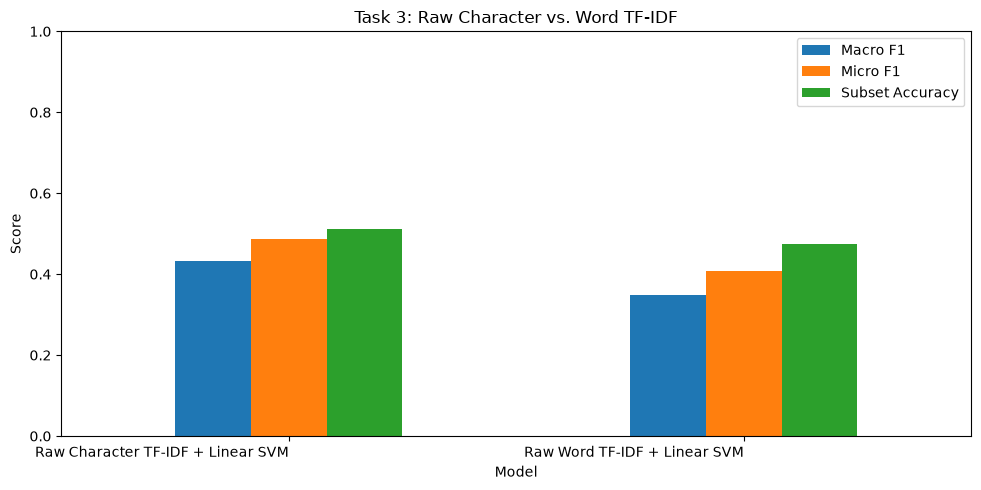

In [36]:
import matplotlib.pyplot as plt

metrics = ["Macro F1", "Micro F1", "Subset Accuracy"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Task 3: Raw Character vs. Word TF-IDF")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=360, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

---

## FastText 

In [19]:
import fasttext
print("FastText imported successfully")

FastText imported successfully


In [16]:
output_dir = Path("task3_fasttext_models")
output_dir.mkdir(parents=True, exist_ok=True)

def clean_for_fasttext(text):
    # Keep raw Burmese text; only remove line breaks
    return str(text).replace("\n", " ").replace("\r", " ").strip()

for label in label_cols:
    train_file = output_dir / f"{label}_train.txt"

    with train_file.open("w", encoding="utf-8") as f:
        for text, target in zip(X_train, y_train[label]):
            text = clean_for_fasttext(text)
            f.write(f"__label__{target} {text}\n")

print("FastText training files created.")

FastText training files created.


In [17]:
label_cols

['stereotype',
 'vilification',
 'dehumanization',
 'extreme_language',
 'lack_of_empathy',
 'invalidation']

In [18]:
labels = [
    "stereotype",
    "vilification",
    "dehumanization",
    "extreme_language",
    "lack_of_empathy",
    "invalidation",
]

In [ ]:
models = {}
predictions = pd.DataFrame(index=range(len(y_test)))
results = []

for label in label_cols:
    print(f"\nTraining FastText for: {label}")

    train_file = output_dir / f"{label}_train.txt"
    model_file = output_dir / f"{label}.bin"

    model = fasttext.train_supervised(
        input=str(train_file),
        lr=0.3,
        epoch=25,
        dim=100,
        wordNgrams=2,
        minn=2,
        maxn=5,
        loss="softmax",
        thread=4,
        verbose=2
    )

    model.save_model(str(model_file))
    models[label] = model

    # Predict each test example
    pred = []

    for text in X_test:
        text = clean_for_fasttext(text)

        # Avoid passing an empty string
        if not text:
            text = " "

        labels, probabilities = model.predict(text, k=1)

        predicted_label = labels[0]
        pred.append(
            1 if predicted_label == "__label__1" else 0
        )

    predictions[label] = pred

    print(f"Saved model: {model_file}")

print("\nAll six classifiers trained.")


Training FastText for: stereotype


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread:  202025 lr:  0.000000 avg.loss:  0.144462 ETA:   0h 0m 0s


Saved model: task3_fasttext_models/stereotype.bin

Training FastText for: vilification


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread:  216275 lr:  0.000000 avg.loss:  0.180479 ETA:   0h 0m 0s


Saved model: task3_fasttext_models/vilification.bin

Training FastText for: dehumanization


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread:  210433 lr:  0.000000 avg.loss:  0.092748 ETA:   0h 0m 0s


Saved model: task3_fasttext_models/dehumanization.bin

Training FastText for: extreme_language


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread:  160273 lr:  0.000000 avg.loss:  0.152871 ETA:   0h 0m 0s


Saved model: task3_fasttext_models/extreme_language.bin

Training FastText for: lack_of_empathy


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread:   34524 lr:  0.000000 avg.loss:  0.126937 ETA:   0h 0m 0s


In [ ]:
import numpy as np
import fasttext

print("NumPy version:", np.__version__)
assert int(np.__version__.split(".")[0]) < 2

In [6]:
# import inspect
# from pathlib import Path
# import fasttext

# # Locate the installed FastText wrapper
# wrapper_path = Path(
#     inspect.getfile(fasttext.FastText._FastText)
# )

# print("FastText wrapper:", wrapper_path)

# # Replace the NumPy-incompatible expression
# source = wrapper_path.read_text(encoding="utf-8")
# old = "np.array(probs, copy=False)"
# new = "np.asarray(probs)"

# if old in source:
#     wrapper_path.write_text(
#         source.replace(old, new),
#         encoding="utf-8"
#     )
#     print("Patch applied successfully.")
# elif new in source:
#     print("Patch already applied.")
# else:
#     print("Expected code not found. No changes made.")

In [1]:
%pwd

'/home/thant_syn/exp/polar'

In [2]:
import fasttext

model = fasttext.load_model(
    "./processed/task3_fasttext_models/stereotype.bin"
)

labels, probabilities = model.predict(
    "မင်းတို့ ဗမာလူမျိုးတွေ နိုင်ငံရေး ဘာသိလို့လည်း",
    k=1
)

print("Predicted labels:", labels)
print("Probabilities:", probabilities)

Predicted labels: ('__label__0',)
Probabilities: [0.94893575]


In [5]:
text = "မင်းတို့ ဗမာလူမျိုးတွေ နိုင်ငံရေး ဘာသိလို့လည်း"

labels, probabilities = model.predict(text, k=3)

for label, probability in zip(labels, probabilities):
    print(f"Label: {label}")
    print(f"Confidence: {probability:.2%}")

Label: __label__0
Confidence: 94.89%
Label: __label__1
Confidence: 5.11%


In [24]:
import os
import fasttext

train_file = "/home/thant_syn/exp/polar/processed/task3_fasttext_models/invalidation_train.txt"
model_path = "/home/thant_syn/exp/polar/processed/task3_fasttext_models/invalidation.bin"

print("Training FastText for: invalidation")
print("Training file exists:", os.path.isfile(train_file))

model = fasttext.train_supervised(
    input=train_file,
    epoch=25,
    lr=0.5,
    wordNgrams=2
)

model.save_model(model_path)

print(f"Saved model: {model_path}")

Training FastText for: invalidation
Training file exists: True


Read 0M words
Number of words:  46922
Number of labels: 2
Progress: 100.0% words/sec/thread: 1068722 lr:  0.000000 avg.loss:  0.046834 ETA:   0h 0m 0s


Saved model: /home/thant_syn/exp/polar/processed/task3_fasttext_models/invalidation.bin


In [25]:
import os
import fasttext

model_dir = "/home/thant_syn/exp/polar/processed/task3_fasttext_models"

labels = [
    "stereotype",
    "vilification",
    "dehumanization",
    "extreme_language",
    "lack_of_empathy",
    "invalidation"
]

for label in labels:
    path = os.path.join(model_dir, f"{label}.bin")

    if os.path.exists(path):
        model = fasttext.load_model(path)
        print(f"✓ {label}: {model.get_labels()}")
    else:
        print(f"✗ {label}: MISSING")

✓ stereotype: ['__label__0', '__label__1']
✓ vilification: ['__label__0', '__label__1']
✓ dehumanization: ['__label__0', '__label__1']
✓ extreme_language: ['__label__0', '__label__1']
✓ lack_of_empathy: ['__label__0', '__label__1']
✓ invalidation: ['__label__0', '__label__1']


In [ ]:
import os
import fasttext
import numpy as np
import pandas as pd

model_dir = "/home/thant_syn/exp/polar/processed/task3_fasttext_models"

labels = [
    "stereotype",
    "vilification",
    "dehumanization",
    "extreme_language",
    "lack_of_empathy",
    "invalidation"
]

models = {}

for label in labels:
    path = os.path.join(model_dir, f"{label}.bin")
    models[label] = fasttext.load_model(path)
    print(f"Loaded: {label}")

In [ ]:
y_true = test_df[labels].astype(int).values
y_pred = np.zeros_like(y_true)

for j, label in enumerate(labels):
    model = models[label]

    for i, text in enumerate(test_df["text"]):
        prediction = model.predict(str(text), k=1)

        predicted_label = prediction[0][0]

        if predicted_label == "__label__1":
            y_pred[i, j] = 1
        else:
            y_pred[i, j] = 0

print("Prediction shape:", y_pred.shape)
print("True shape:", y_true.shape)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

subset_accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

micro_precision = precision_score(
    y_true, y_pred,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    y_true, y_pred,
    average="micro",
    zero_division=0
)

micro_f1 = f1_score(
    y_true, y_pred,
    average="micro",
    zero_division=0
)

print("===== Task 3 FastText Overall Metrics =====")
print(f"Subset Accuracy : {subset_accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")
print(f"Micro Precision : {micro_precision:.4f}")
print(f"Micro Recall    : {micro_recall:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")